# OSSE: North Atlantic Hurricane

An observing system simulation experiment (OSSE) evaluates how well an observing system, real or planned, would observe a phenomenon, by sampling a high-resolution model simulation (the *nature run*) as the system would. This example is an OSSE of a **hurricane** in the 7-km [GEOS-5 Nature Run (G5NR)](https://gmao.gsfc.nasa.gov/global_mesoscale/7km-G5NR/). In late August of the Nature Run's second year, a simulated hurricane crosses the North Atlantic from near the Cape Verde Islands (about 15 N, 27 W on 20 August) to Nova Scotia (30 August). This example covers two days, 25 and 26 August, when the storm passes north of Puerto Rico and Hispaniola and begins to recurve to the north.

The observing systems are the same as in the [monsoon OSSE](RunOSSEMonsoon.ipynb): the atmospheric sounders on the current NOAA/NASA polar-orbiting satellites ([ATMS](../../validation/instruments/ValidateImagerATMS.ipynb) and [CrIS](../../validation/instruments/ValidateImagerCrIS.ipynb)) and two notional future sounders with finer resolution. Unlike the monsoon, whose features are scattered convective cells over land with a strong diurnal cycle, the features here are organized around one large storm over the ocean. Two kinds of features are defined:

* **cold cloud tops**, as in the monsoon OSSE, which outline the storm's central dense overcast and the convective cells of its rainbands; and
* **heavy precipitation**, which outlines its eyewall and rainbands, where microwave sounders sense the rain and ice beneath the cloud tops.

The experiment asks the same two questions about each feature:

1. **Is it observed?** Does a sounder's swath cover the feature?
2. **Is it resolved?** Is the part of the feature that is observed at least a few resolution elements (footprints or the spacing between them) across?

The steps are:

1. configure the scenario;
2. locate the storm in the coarsened (0.5 degree) Nature Run;
3. configure the Nature Run (7 km) around the storm;
4. define the features (cold cloud tops and heavy precipitation) in each 30-minute frame;
5. define the sensors;
6. compute the ground tracks (swaths) of the satellites over the study region with TAT-C;
7. determine whether each feature is observed and resolved by each sensor;
8. generate a visualization and statistics; and
9. trade the design of the constellation: the number of satellites and their orbit planes.

The example is designed to run in a few minutes, and the constellation trade in a few more, after a one-time download of the Nature Run around the storm (about 100 MB, which takes several minutes). It requires the optional dependencies for OSSE examples (`pip install tatc[osse]`).

## Configure the Scenario

The study region (15-34 N, 77-58.5 W) is a box around the storm's track over the two days, at least 6 degrees from the storm center at all times, so that it contains the storm's clouds and rainbands as well as some convection of its environment. It is mostly ocean, with the northern coasts of Puerto Rico and Hispaniola and the Bahamas.

The Nature Run covers 15 May 2005 to 16 June 2007 and does not correspond to any real year. As in the monsoon OSSE, the satellite orbits (those of 25 August 2026, from operational element sets) are paired with the Nature Run on the same calendar date, here in its second year (2006), in which the storm occurs. Because the orbits are sun-synchronous, the local solar times at which they observe do not depend on the date.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import box

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# study region: a box around the storm's track over the two days
domain = box(-77, 15, -58.5, 34)
# the simulated orbits and the nature run (the same calendar date in the Nature Run's second year)
start = datetime(2026, 8, 25, tzinfo=timezone.utc)
nature_start = start.replace(year=2006)
duration = timedelta(days=2)
frame_duration = timedelta(minutes=30)  # the Nature Run's time-averaging interval
n_frames = int(duration / frame_duration)

## Locate the Storm

The full-resolution (7 km) Nature Run is too large to search a whole ocean basin over a season. Its coarsened collections (0.5 degrees, hourly) are about 200 times smaller per time step and suffice to find and track storms: this storm was found as the deepest low in the sea-level pressure (`slp`) of the coarsened collection over the North Atlantic around 25 August. Here, the storm center at each hour is the minimum sea-level pressure in the study region, and the storm's strength is given by the minimum pressure and the maximum 10 m wind speed (`u10m`, `v10m`) in the region. Both are smoothed by the coarse grid, so the storm at full resolution is somewhat deeper and stronger.

In [2]:
import xarray as xr

G5NR_URL = "https://opendap.nccs.nasa.gov/dods/OSSE/G5NR/Ganymed/7km"
COARSE_URL = f"{G5NR_URL}/0.5000_deg/inst/inst01hr_2d_met1_Cx"


def naive(time):
    """A time without its time zone, as the Nature Run's time coordinate."""
    return time.replace(tzinfo=None)


coarse_file = (
    DATA_DIR / f"g5nr_hurricane_coarse_{nature_start:%Y%m%d}_{duration.days}d.nc"
)
if not coarse_file.exists():
    minx, miny, maxx, maxy = domain.bounds
    with xr.open_dataset(COARSE_URL) as remote:
        remote[["slp", "u10m", "v10m"]].sel(
            time=slice(naive(nature_start), naive(nature_start + duration)),
            lon=slice(minx, maxx),
            lat=slice(miny, maxy),
        ).load().to_netcdf(coarse_file)
coarse = xr.load_dataset(coarse_file)

# the storm center (the minimum sea-level pressure in the study region) and strength at each hour
slp = coarse.slp.stack(cell=("lat", "lon"))
center = slp.isel(cell=slp.argmin("cell"))
track = pd.DataFrame(
    {
        "lat": center.lat.values,
        "lon": center.lon.values,
        "min_slp_hpa": center.values / 100,
        "max_wind_ms": np.hypot(coarse.u10m, coarse.v10m).max(("lat", "lon")).values,
    },
    index=pd.DatetimeIndex(coarse.time.values, name="time"),
)
track.iloc[::6].round(1)

,lat,lon,min_slp_hpa,max_wind_ms
time,,,,
2006-08-25 00:00:00,21.0,-64.5,962.900024,39.299999
2006-08-25 06:00:00,21.5,-66.0,960.099976,41.500000
2006-08-25 12:00:00,22.0,-67.5,962.500000,39.200001
2006-08-25 18:00:00,23.0,-68.5,963.000000,40.200001
2006-08-26 00:00:00,23.5,-69.5,958.700012,42.000000
2006-08-26 06:00:00,24.5,-70.0,958.299988,40.599998
2006-08-26 12:00:00,25.5,-70.5,955.700012,41.500000
2006-08-26 18:00:00,27.0,-70.5,956.599976,44.799999
2006-08-27 00:00:00,28.0,-71.0,951.799988,41.799999


## Configure the Nature Run

The full-resolution (0.0625 degree, about 7 km) fields are needed only around the storm, so only the study region is requested. As in the monsoon OSSE, this example uses the single-level, 30-minute time-averaged diagnostics, and reads the upwelling longwave flux at the top of the atmosphere (`lwtup`), a proxy for cloud-top temperature, the total precipitation rate (`prectot`), and its convective part (`preccon`). In a hurricane, much of the rain falls from the storm's resolved circulation rather than from parameterized convection, so the features use the total rate. The fields are requested in 12-hour chunks, each checked for a field of zeros, which the server has been found to return in place of a field for some large requests, and saved in a local `data/osse` directory, so later runs are fast.

In [3]:
NATURE_URL = f"{G5NR_URL}/0.0625_deg/tavg/tavg30mn_2d_met3_Nx"
GRID_SIZE = 0.0625  # deg
VARIABLES = ["lwtup", "prectot", "preccon"]
CHUNK = timedelta(hours=12)


def fetch_chunk(remote, chunk_start):
    """One chunk of the Nature Run over the study region, retried if the server returns a field of zeros."""
    minx, miny, maxx, maxy = domain.bounds
    for attempt in range(4):
        chunk = (
            remote[VARIABLES]
            .sel(
                time=slice(
                    naive(chunk_start),
                    naive(chunk_start + CHUNK - timedelta(seconds=1)),
                ),
                lon=slice(minx, maxx),
                lat=slice(miny, maxy),
            )
            .load()
        )
        if float((chunk["lwtup"] == 0).mean()) < 0.5:
            return chunk
    raise RuntimeError(f"the server returned a field of zeros for {chunk_start}")


nature_file = DATA_DIR / f"g5nr_hurricane_{nature_start:%Y%m%d}_{duration.days}d.nc"
if not nature_file.exists():
    with xr.open_dataset(NATURE_URL) as remote:
        chunks = [
            fetch_chunk(remote, nature_start + k * CHUNK)
            for k in range(int(duration / CHUNK))
        ]
    xr.concat(chunks, "time").to_netcdf(nature_file)
nature = xr.load_dataset(nature_file)
assert nature.sizes["time"] == n_frames
assert float((nature["lwtup"] == 0).mean()) == 0
# each time stamp is the middle of its 30-minute averaging interval
assert (nature.time.values[0] - np.datetime64(naive(nature_start))) == np.timedelta64(
    15, "m"
)
nature

<xarray.Dataset> Size: 104MB
Dimensions:  (time: 96, lat: 305, lon: 297)
Coordinates:
  * time     (time) datetime64[ns] 768B 2006-08-25T00:15:00 ... 2006-08-26T23...
  * lat      (lat) float64 2kB 15.0 15.06 15.12 15.19 ... 33.81 33.88 33.94 34.0
  * lon      (lon) float64 2kB -77.0 -76.94 -76.88 ... -58.62 -58.56 -58.5
Data variables:
    lwtup    (time, lat, lon) float32 35MB 172.8 172.8 173.4 ... 291.4 290.9
    prectot  (time, lat, lon) float32 35MB 1.875e-05 1.425e-05 ... 1.246e-06
    preccon  (time, lat, lon) float32 35MB 1.785e-05 1.389e-05 ... 1.241e-06
Attributes:
    title:                2d,30-Minute,Time-Averaged,Single-Level,Full Resolu...
    Conventions:          COARDS\nGrADS
    dataType:             Grid
    history:              Fri Nov 06 10:10:56 EST 2026 : imported by GrADS Da...
    extra_das_attribute:  This is an example of metadata added using a supple...

## Define the Environmental Features

Features are contiguous patches of grid cells of one of two kinds:

* **cold cloud top**: an upwelling longwave flux below that of a 220 K blackbody (about 133 W m-2), as in the monsoon OSSE; and
* **heavy precipitation**: a total precipitation rate above `PRECIP_THRESHOLD` (10 mm/h).

Each patch in each frame is a feature, and, as in the monsoon OSSE, patches smaller than the Nature Run's effective resolution (`EFFECTIVE_RESOLUTION_KM`, four grid spacings or 28 km) are discarded. A large patch of cold cloud tops may contain several patches of heavy precipitation, so the two kinds overlap.

For each feature, the notebook records its area, the diameter of a circle of the same area (its size), the area-weighted centroid, its coldest flux, its highest and total precipitation rates, and its distance from the storm center at the middle of its frame (interpolated from the hourly track). Features within `STORM_RADIUS_KM` (500 km) of the center are attributed to the storm and the others to its environment.

In [4]:
import scipy.ndimage as ndi

from tatc.constants import EARTH_MEAN_RADIUS

THRESHOLD = (
    5.67037e-8 * 220**4
)  # W m-2, the upwelling longwave flux of a 220 K blackbody
PRECIP_THRESHOLD = 10 / 3600  # kg m-2 s-1 (10 mm/h)
EFFECTIVE_RESOLUTION_KM = (
    4 * 7
)  # km, several grid spacings (Gelaro et al., 2015); smaller features are not resolved
STORM_RADIUS_KM = 500  # km, features within this distance of the storm center are attributed to the storm
KINDS = {
    "cold cloud top": lambda frame: frame["lwtup"].values < THRESHOLD,
    "heavy precipitation": lambda frame: frame["prectot"].values > PRECIP_THRESHOLD,
}


def find_features(nature, kind):
    """The features of a kind (contiguous patches at least EFFECTIVE_RESOLUTION_KM in size) in each frame."""
    lon, lat = nature.lon.values, nature.lat.values
    lon2d, lat2d = np.meshgrid(lon, lat)
    cell_area = (EARTH_MEAN_RADIUS * np.radians(GRID_SIZE)) ** 2 * np.cos(
        np.radians(lat2d)
    )  # m^2

    records, polygons = [], []
    for frame in range(nature.sizes["time"]):
        fields = nature.isel(time=frame)
        lwtup, prectot = fields["lwtup"].values, fields["prectot"].values
        labels, n_labels = ndi.label(
            KINDS[kind](fields)
        )  # contiguous cells of the kind
        if n_labels == 0:
            continue
        ids = np.arange(1, n_labels + 1)
        area = ndi.sum(cell_area, labels, ids)
        n_cells = ndi.sum(np.ones_like(lwtup), labels, ids).astype(int)
        # polygons are the unions of the cells, which are centered on the grid points
        j, i = np.nonzero(labels)
        order = np.argsort(labels[j, i], kind="stable")
        j, i = j[order], i[order]
        cells = shapely.box(
            lon[i] - GRID_SIZE / 2,
            lat[j] - GRID_SIZE / 2,
            lon[i] + GRID_SIZE / 2,
            lat[j] + GRID_SIZE / 2,
        )
        for k, cluster in enumerate(np.split(cells, np.cumsum(n_cells)[:-1])):
            records.append(
                {
                    "frame": frame,
                    "kind": kind,
                    "n_cells": n_cells[k],
                    "area_km2": area[k] / 1e6,
                    "lon": ndi.sum(cell_area * lon2d, labels, ids[k]) / area[k],
                    "lat": ndi.sum(cell_area * lat2d, labels, ids[k]) / area[k],
                    "min_lwtup": ndi.minimum(lwtup, labels, ids[k]),
                    "max_prectot_mmh": ndi.maximum(prectot, labels, ids[k]) * 3600,
                    "tot_prectot": ndi.sum(prectot * cell_area, labels, ids[k]),
                }
            )
            polygons.append(shapely.union_all(cluster))

    features = gpd.GeoDataFrame(records, geometry=polygons, crs="EPSG:4326")
    features["diameter_km"] = np.sqrt(
        4 * features.area_km2 / np.pi
    )  # of a circle of equal area
    return features[features.diameter_km >= EFFECTIVE_RESOLUTION_KM]


features = pd.concat([find_features(nature, kind) for kind in KINDS], ignore_index=True)
features["time"] = start + features.frame * frame_duration

# distance (great circle) from the storm center at the middle of the frame, interpolated from the hourly track
frame_middle = (
    nature.time.values[features.frame] - track.index.values[0]
) / np.timedelta64(1, "h")
track_hours = (track.index.values - track.index.values[0]) / np.timedelta64(1, "h")
center_lat = np.radians(np.interp(frame_middle, track_hours, track.lat))
center_lon = np.radians(np.interp(frame_middle, track_hours, track.lon))
lat, lon = np.radians(features.lat), np.radians(features.lon)
features["storm_distance_km"] = (
    EARTH_MEAN_RADIUS
    / 1e3
    * np.arccos(
        np.clip(
            np.sin(lat) * np.sin(center_lat)
            + np.cos(lat) * np.cos(center_lat) * np.cos(lon - center_lon),
            -1,
            1,
        )
    )
)
features["region"] = np.where(
    features.storm_distance_km < STORM_RADIUS_KM, "storm", "environment"
)
features.groupby(["kind", "region"]).agg(
    features=("frame", "size"),
    median_diameter_km=("diameter_km", "median"),
    max_diameter_km=("diameter_km", "max"),
    max_prectot_mmh=("max_prectot_mmh", "max"),
).round(1)

features  median_diameter_km  \
kind                region                                      
cold cloud top      environment       190                51.7   
                    storm             355                56.4   
heavy precipitation environment        51                31.7   
                    storm             517                49.2   

                                 max_diameter_km  max_prectot_mmh  
kind                region                                         
cold cloud top      environment            115.3       182.199997  
                    storm                  483.0       102.000000  
heavy precipitation environment             46.0       209.800003  
                    storm                  215.1       134.300003

## Define the Sensors

The platforms, swaths, and sensors are those of the monsoon OSSE (see there for their basis): ATMS and CrIS on NOAA-20 and NOAA-21 (the current constellation, since Suomi NPP was decommissioned), with the swaths of TAT-C's [instrument catalog](../../validation/catalog.rst), tested against NOAA-20 data, and the notional future microwave (MW) and infrared (IR) sounders with finer resolution, sharing the ATMS and CrIS swaths. Here the element sets are those of 25 August 2026.

In [5]:
from tatc.catalog import get_entry
from tatc.schemas import GeneralPerturbationsOrbit, PointedInstrument, Satellite
from tatc.utils import compute_ground_inertial_velocity

# element sets (epoch 2026-08-25 00:00 UTC) from the JPSS TLE-AUX archive, as in the validation notebooks
tles = {
    "NOAA-20": [
        "1 43013U 17073A   26237.00000000  .00000082  00000-0  38818-4 0  2185",
        "2 43013 098.7794 175.8588 0001924 083.1912 240.0420 14.19522547454239",
    ],
    "NOAA-21": [
        "1 54234U 22150A   26237.00000000  .00000066  00000-0  31364-4 0  9878",
        "2 54234 098.7078 174.6381 0001971 035.6178 125.9881 14.19546491196315",
    ],
}
orbits = {name: GeneralPerturbationsOrbit.from_tle(tle) for name, tle in tles.items()}

# the instrument catalog's entries of ATMS and CrIS, and their swath configurations tested on NOAA-20
entries = {"ATMS": get_entry("atms"), "CrIS": get_entry("cris")}
SWATHS = {"ATMS": "swath_noaa_20", "CrIS": "swath"}
TIME_STEP = 30  # s, of the ground track


def sounder_satellite(name, orbit):
    """A satellite carrying the swaths of ATMS and CrIS (the catalog's swath configurations), tailored to the time
    step, with the attitude they were tested with (scanning perpendicular to the inertial velocity)."""
    payloads = [
        entry.build(
            configuration=SWATHS[sensor], orbit=orbit, time_step=TIME_STEP
        )
        for sensor, entry in entries.items()
    ]
    return Satellite(
        name=name,
        orbit=orbit,
        instruments=[payload.instruments[0] for payload in payloads],
        attitude=payloads[0].attitude,
    )


satellites = [sounder_satellite(name, orbit) for name, orbit in orbits.items()]

REFERENCE_RANGE_KM = 830  # nominal slant range at nadir (altitude), at which the nominal resolutions apply
# angular spacing (deg) of the samples of each scan, from the catalog's configurations of their samples: the ATMS scan
# positions and the pitch of the CrIS 3 x 3 array of views
atms_beams = entries["ATMS"].configurations["beams_noaa_20"].instruments[0].parameters
cris_pixels = entries["CrIS"].configurations["pixels"].instruments[0].parameters
SAMPLING_DEG = {
    "ATMS": atms_beams["cross_track_field_of_view"] / atms_beams["cross_track_pixels"],
    "CrIS": cris_pixels["along_track_field_of_view"] / cris_pixels["along_track_pixels"],
}
# sensors: the scan (swath) they share, and their horizontal resolution at nadir (km)
sensors = pd.DataFrame(
    [
        {"sensor": "ATMS", "swath": "ATMS", "horizontal_km": 32},
        {"sensor": "CrIS", "swath": "CrIS", "horizontal_km": 14},
        {"sensor": "Future MW", "swath": "ATMS", "horizontal_km": 10},
        {"sensor": "Future IR", "swath": "CrIS", "horizontal_km": 3},
    ]
).set_index("sensor")
# sample spacing at nadir (km): that of the heritage sensor, scaled for the future sensors in proportion to their footprint
heritage_km = sensors.horizontal_km[sensors.swath].values
sensors["sampling_km"] = (
    REFERENCE_RANGE_KM
    * np.radians(sensors.swath.map(SAMPLING_DEG))
    * sensors.horizontal_km
    / heritage_km
)
# the time between scans (s) of the future sensors, each of which scans one row of samples every time the ground track
# advances by its sample spacing, so that its samples are spaced along track by that advance (ATMS and CrIS keep the
# angular pitch of their samples along track)
ground_speed_km_s = (
    compute_ground_inertial_velocity(orbits["NOAA-20"].get_mean_altitude()) / 1e3
)
sensors["scan_period_s"] = np.where(
    sensors.swath != sensors.index, sensors.sampling_km / ground_speed_km_s, np.nan
)


def sensor_instrument(sensor):
    """The swath instrument of a sensor with its pixels (for its sample sizes, see `compute_sample_sizes`): pixels
    spaced by the angle that the sample spacing subtends at nadir from the reference range (enough to span the
    swath), each with the instantaneous field of view that its horizontal resolution subtends, along and across
    track, and for a future sensor the time between its scans (`scan_period`), in which the ground track advances
    by its sample spacing."""
    row = sensors.loc[sensor]
    swath = satellites[1].instruments[list(entries).index(row.swath)]
    ifov = np.degrees(2 * np.arctan(row.horizontal_km / 2 / REFERENCE_RANGE_KM))
    spacing = np.degrees(row.sampling_km / REFERENCE_RANGE_KM)
    pixels = round(swath.cross_track_field_of_view / spacing)
    # the oversampling makes each pixel's field of view ifov (negative: a gap between pixels)
    return PointedInstrument(
        **swath.model_dump(
            exclude_unset=True,
            exclude={
                "cross_track_field_of_view",
                "along_track_field_of_view",
                "cross_track_pixels",
                "cross_track_oversampling",
                "along_track_oversampling",
                "scan_period",
            }
        ),
        cross_track_field_of_view=pixels * spacing,
        along_track_field_of_view=spacing,
        cross_track_pixels=pixels,
        cross_track_oversampling=1 - spacing / ifov,
        along_track_oversampling=1 - spacing / ifov,
        scan_period=None if np.isnan(row.scan_period_s) else row.scan_period_s,
    )


sensors.round(1)

,swath,horizontal_km,sampling_km,scan_period_s
sensor,,,,
ATMS,ATMS,32,16.1,NaN
CrIS,CrIS,14,15.8,NaN
Future MW,ATMS,10,5.0,0.8
Future IR,CrIS,3,3.4,0.5


## Compute the Ground Tracks

`collect_ground_track` returns the footprint of each instrument at each time step, clipped to the study region (the `mask`), which are tabulated per frame and combined (`swaths`) to find the area each swath covers in each frame.

In [6]:
from tatc.analysis import collect_ground_track


def collect_tracks(satellites, duration):
    """The footprint of every instrument of the satellites at each time step over a duration from start, clipped to the
    study region, with its frame."""
    times = [
        start + timedelta(seconds=TIME_STEP * (i + 0.5))
        for i in range(int(duration.total_seconds() // TIME_STEP))
    ]
    tracks = collect_ground_track(satellites, times, instrument_index=None, mask=domain)
    tracks = tracks[tracks.valid_obs].reset_index(drop=True)
    tracks["geometry"] = shapely.force_2d(tracks.geometry.values)
    tracks["frame"] = ((tracks.time - start) // frame_duration).astype(int)
    return tracks


tracks = collect_tracks(satellites, duration)
# the area swept by each swath (ATMS or CrIS) in each frame
swaths = tracks.groupby(["frame", "instrument"]).geometry.agg(shapely.union_all)
tracks.groupby(["satellite", "instrument"]).agg(
    footprints=("time", "size"), first=("time", "min"), last=("time", "max")
)

footprints                     first  \
satellite instrument                                         
NOAA-20   ATMS                96 2026-08-25 05:55:45+00:00   
          CrIS                92 2026-08-25 05:55:45+00:00   
NOAA-21   ATMS                80 2026-08-25 05:00:15+00:00   
          CrIS                69 2026-08-25 05:00:15+00:00   

                                          last  
satellite instrument                            
NOAA-20   ATMS       2026-08-26 18:37:15+00:00  
          CrIS       2026-08-26 18:37:15+00:00  
NOAA-21   ATMS       2026-08-26 17:41:45+00:00  
          CrIS       2026-08-26 17:41:45+00:00

## Compute Observability and Resolution

As in the monsoon OSSE, a feature is **observed** by a swath if the swath footprint of some time step in its frame overlaps it, a **look** is one satellite's view of the part of a feature inside its swath, and a feature is **resolved** if its viewed part spans at least `RESOLUTION_FACTOR` (two) resolution elements at its best look. TAT-C's `collect_feature_observations` collects the looks at features that exist for a period of time (here, each feature's frame), with the viewing geometry of each. The resolution element is the larger of a sensor's pixel and the spacing between its pixels, projected onto the ground at the look by TAT-C's `compute_sample_sizes` along and across track (see the monsoon OSSE), with its size measured as the diameter of a circle of the same area (`ELEMENT_AXIS`). The statistics also give the share resolved with the footprint and the spacing added in quadrature (`"quadrature"`), a bound on the element where the two are similar (see the monsoon OSSE).

In [7]:
from tatc.analysis import collect_feature_observations, compute_sample_sizes

RESOLUTION_FACTOR = 2  # a feature is resolved if its viewed part spans at least this many resolution elements
ELEMENT_AXIS = "equivalent"  # the size of a resolution element: "equivalent" (diameter of equal area), "cross-track",
# or "quadrature" (the equivalent diameter with the footprint and the spacing added in quadrature)
AXES = ["equivalent", "cross-track", "quadrature"]


def collect_looks(satellites, duration, features):
    """The looks at the features (see `collect_feature_observations`): each satellite's view of the part of each
    feature inside its swath in the feature's frame, at the time of the footprint that covers most of it, with the
    size of the viewed part and the slant range and zenith angle at its centroid."""
    times = [
        start + timedelta(seconds=TIME_STEP * (i + 0.5))
        for i in range(int(duration.total_seconds() // TIME_STEP))
    ]
    looks = collect_feature_observations(
        features.assign(start=features.time, end=features.time + frame_duration),
        satellites,
        times,
    )
    looks["viewed_km"] = np.sqrt(
        4 * looks.viewed_fraction * features.area_km2.values[looks.feature] / np.pi
    )
    looks["range_m"], looks["zenith"] = looks.sat_range, 90 - looks.sat_alt
    return looks


def assess(looks, features, satellites):
    """Whether each sensor observes and resolves each feature, from its best look."""
    results = []
    for sensor, row in sensors.iterrows():
        # the sizes of the sensor's samples at its looks, flown on the same satellites
        sensor_satellites = [
            satellite.model_copy(update={"instruments": [sensor_instrument(sensor)]})
            for satellite in satellites
        ]
        sensor_looks = compute_sample_sizes(
            looks[looks.instrument == row.swath], sensor_satellites
        )
        # the resolution element is the larger of a sample and the spacing between samples (km), along and across track
        along = np.maximum(sensor_looks.sample_along, sensor_looks.spacing_along) / 1e3
        cross = np.maximum(sensor_looks.sample_cross, sensor_looks.spacing_cross) / 1e3
        # or, as a bound, the two added in quadrature (as independent blurs)
        along_q = np.hypot(sensor_looks.sample_along, sensor_looks.spacing_along) / 1e3
        cross_q = np.hypot(sensor_looks.sample_cross, sensor_looks.spacing_cross) / 1e3
        for axis, element_km in {
            "equivalent": np.sqrt(along * cross),
            "cross-track": cross,
            "quadrature": np.sqrt(along_q * cross_q),
        }.items():
            sensor_looks[f"elements ({axis})"] = sensor_looks.viewed_km / element_km
            if axis == ELEMENT_AXIS:
                sensor_looks["element_km"] = element_km
        # the best look at each feature: the one whose viewed part spans the most resolution elements
        best = sensor_looks.loc[
            sensor_looks.groupby("feature")[f"elements ({ELEMENT_AXIS})"].idxmax()
        ].set_index("feature")
        result = features[
            ["frame", "kind", "region", "diameter_km", "area_km2", "tot_prectot"]
        ].copy()
        result["sensor"] = sensor
        result["looks"] = (
            sensor_looks.groupby("feature").size().reindex(result.index, fill_value=0)
        )
        result["observed"] = result.looks > 0
        result = result.join(
            best[["satellite", "zenith", "viewed_fraction", "viewed_km", "element_km"]]
        )
        for axis in AXES:
            result[f"elements ({axis})"] = sensor_looks.groupby("feature")[
                f"elements ({axis})"
            ].max()
        result["resolved"] = result[f"elements ({ELEMENT_AXIS})"] >= RESOLUTION_FACTOR
        results.append(result)
    return pd.concat(results).reset_index().rename(columns={"index": "feature"})


looks = collect_looks(satellites, duration, features)
results = assess(looks, features, satellites)
results.groupby(["kind", "sensor"])[["observed", "resolved"]].sum().unstack("kind")

observed                           resolved  \
kind      cold cloud top heavy precipitation cold cloud top   
sensor                                                        
ATMS                  62                  38             17   
CrIS                  49                  29             32   
Future IR             49                  29             49   
Future MW             62                  38             50   

                               
kind      heavy precipitation  
sensor                         
ATMS                       12  
CrIS                       19  
Future IR                  28  
Future MW                  30

## Generate a Visualization

The figure shows the heavy precipitation features of one frame, the one with the most such features whose status differs between the sensors, colored by whether each sensor resolves them (blue), observes but does not resolve them (orange), or does not observe them (faded, outside the swath). The underlying image is the Nature Run's upwelling longwave flux, whose dark areas are cold cloud tops, and the line is the storm's track over the two days, with its center in the frame marked.

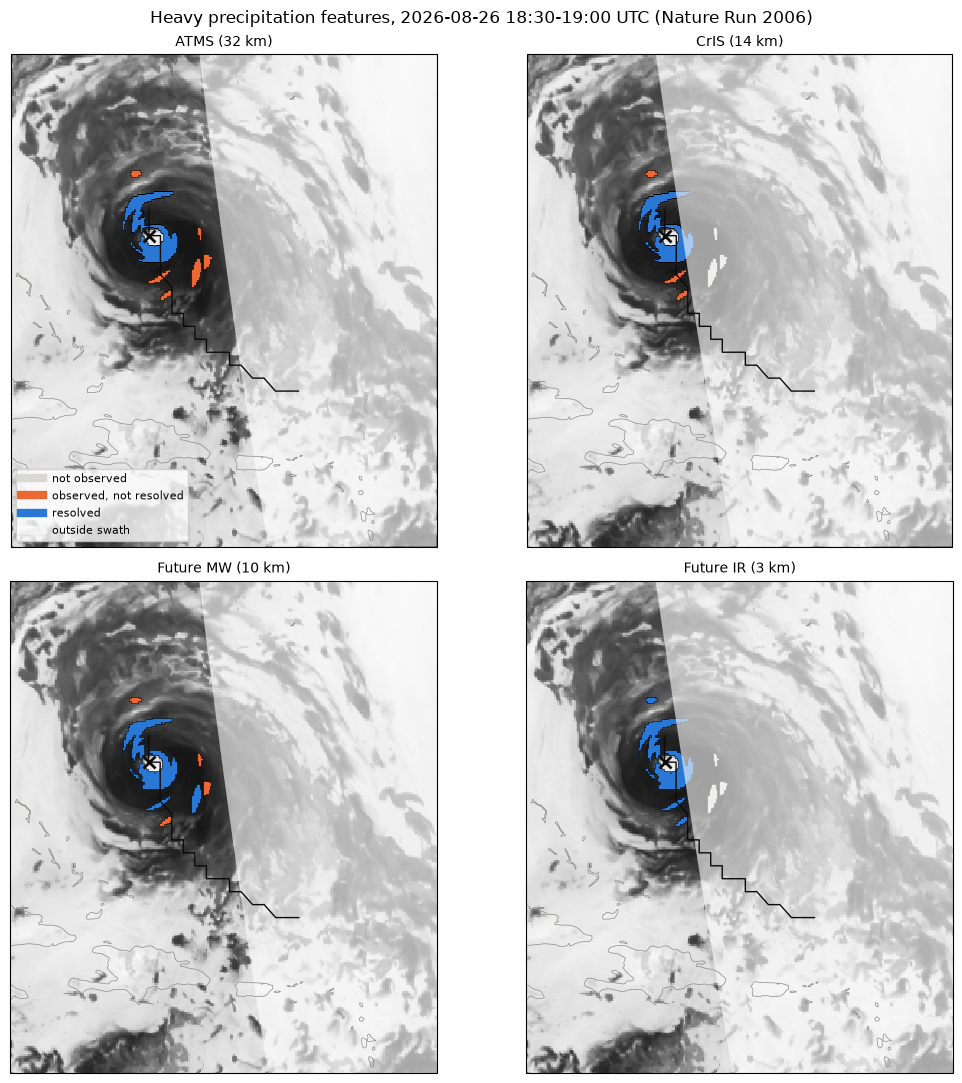

In [8]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

KIND = "heavy precipitation"
# the frame with the most features of the kind whose status (not observed, observed, or resolved) differs between the sensors
of_kind = results[results.kind == KIND]
status = of_kind.observed.astype(int) + of_kind.resolved.astype(int)
example = (
    (status.groupby([of_kind.frame, of_kind.feature]).nunique() > 1)
    .groupby("frame")
    .sum()
    .idxmax()
)
example_time = start + example * frame_duration
example_center = track.iloc[
    np.abs(track.index - pd.Timestamp(nature.time.values[example])).argmin()
]
STATUS = {
    "not observed": "#d9d8d3",
    "observed, not resolved": "#eb6834",
    "resolved": "#2a78d6",
}

fig, axes = plt.subplots(
    2, 2, figsize=(11, 11), subplot_kw={"projection": ccrs.PlateCarree()}
)
for ax, sensor in zip(axes.ravel(), sensors.index):
    background = nature["lwtup"].isel(time=example)
    ax.pcolormesh(
        background.lon,
        background.lat,
        background,
        cmap="Greys_r",
        vmin=100,
        vmax=320,
        shading="auto",
        transform=ccrs.PlateCarree(),
    )
    members = of_kind[(of_kind.sensor == sensor) & (of_kind.frame == example)]
    member_status = np.where(
        members.resolved,
        "resolved",
        np.where(members.observed, "observed, not resolved", "not observed"),
    )
    for label, color in STATUS.items():
        selected = features.loc[members.feature[member_status == label]]
        if len(selected):
            selected.plot(
                ax=ax,
                facecolor=color,
                edgecolor="black",
                linewidth=0.4,
                transform=ccrs.PlateCarree(),
            )
    # fade the part of the study region outside the swath
    swath = swaths.get((example, sensors.loc[sensor, "swath"]))
    outside = domain if swath is None else domain.difference(swath)
    ax.add_geometries(
        [outside],
        crs=ccrs.PlateCarree(),
        facecolor="white",
        edgecolor="none",
        alpha=0.6,
    )
    ax.add_feature(cfeature.COASTLINE, edgecolor="#8a8984", linewidth=0.5)
    ax.plot(track.lon, track.lat, color="#0b0b0b", lw=1, transform=ccrs.PlateCarree())
    ax.plot(
        example_center.lon,
        example_center.lat,
        marker="x",
        ms=8,
        mew=2,
        color="#0b0b0b",
        transform=ccrs.PlateCarree(),
    )
    ax.set_extent(
        [domain.bounds[0], domain.bounds[2], domain.bounds[1], domain.bounds[3]]
    )
    ax.set_title(f"{sensor} ({sensors.loc[sensor, 'horizontal_km']} km)", fontsize=10)
for label, color in STATUS.items():
    axes[0, 0].plot([], [], color=color, lw=6, label=label)
axes[0, 0].plot([], [], color="#ffffff", lw=6, alpha=0.6, label="outside swath")
axes[0, 0].legend(loc="lower left", fontsize=8, frameon=True)
fig.suptitle(
    f"Heavy precipitation features, {example_time:%Y-%m-%d %H:%M}-{example_time + frame_duration:%H:%M} UTC (Nature Run {nature_start:%Y})"
)
fig.tight_layout()
plt.show()

The animation steps through every frame of the two days, with each sensor's heavy precipitation features colored as in the figure (drawn over the faded part of the study region outside the swaths of each frame, so that the features not observed remain visible), the storm's center (the cross) on its track, and a running count of the features each sensor has resolved in the study region. The maps follow the storm: they show a window of `VIEW_DEG` degrees around its track (smoothed over six hours, and kept within the study region), in which the features of the storm are large enough to see. The timeline below it gives the number of heavy precipitation features in each frame (gray) and the frames in which the satellites pass (black ticks), in local solar time at the center of the study region. It is saved as a GIF in the `data` directory (it is not embedded here, for its size).

In [9]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from PIL import Image as PILImage

ANIMATION_FILE = DATA_DIR / "hurricane_feature_status.gif"
FPS = 6  # frames of the nature run per second of the animation
DPI = 80  # pixels per inch of the animation
VIEW_DEG = 10  # deg, the width and height of the maps, which follow the storm
INK, GRAY_EDGE = "#0b0b0b", "#8a8984"


def save_gif(fig, update, n_frames, path, fps, colors):
    """Saves an animation as a GIF with one layout and one palette (a ramp of grays and the given colors) for all
    frames, without dithering, which keeps the colors of the features exact and compresses far better than a palette
    per frame.
    """
    grays = [(v, v, v) for v in np.linspace(0, 255, 96).round().astype(int)]
    rgb = grays + [
        tuple(int(color[i : i + 2], 16) for i in (1, 3, 5)) for color in colors
    ]
    palette = PILImage.new("P", (1, 1))
    palette.putpalette(
        [v for color in rgb for v in color] + [255] * 3 * (256 - len(rgb))
    )
    fig.set_dpi(DPI)
    # lay the figure out once and keep it: a layout recomputed for each frame (as its titles change) moves the
    # panels by a pixel or so from frame to frame
    update(0)
    fig.canvas.draw()
    fig.set_layout_engine("none")
    frames = []
    for k in range(n_frames):
        update(k)
        fig.canvas.draw()
        image = PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3])
        frames.append(image.quantize(palette=palette, dither=PILImage.Dither.NONE))
    frames[0].save(
        path,
        save_all=True,
        append_images=frames[1:],
        duration=round(1000 / fps),
        loop=0,
        optimize=True,
    )


# local mean solar time at the center of the study region
SOLAR_OFFSET = timedelta(hours=(domain.bounds[0] + domain.bounds[2]) / 2 / 15)

frame_starts = [start + k * frame_duration for k in range(n_frames)]
local_starts = [(t + SOLAR_OFFSET).replace(tzinfo=None) for t in frame_starts]
features_per_frame = (
    features[features.kind == KIND]
    .groupby("frame")
    .size()
    .reindex(range(n_frames), fill_value=0)
)
pass_frames = sorted({frame for frame, _ in swaths.index})
# the storm's center in each frame (at the hour nearest the middle of the frame)
centers = track.iloc[
    [np.abs(track.index - pd.Timestamp(t)).argmin() for t in nature.time.values]
]
# the centers of the maps: the storm's track smoothed over six hours, kept within the study region
smooth = track[["lon", "lat"]].rolling(6, center=True, min_periods=1).mean()
views = smooth.iloc[
    [np.abs(track.index - pd.Timestamp(t)).argmin() for t in nature.time.values]
].copy()
views["lon"] = views.lon.clip(
    domain.bounds[0] + VIEW_DEG / 2, domain.bounds[2] - VIEW_DEG / 2
)
views["lat"] = views.lat.clip(
    domain.bounds[1] + VIEW_DEG / 2, domain.bounds[3] - VIEW_DEG / 2
)
# the status of each feature of the kind for each sensor
animated = of_kind.assign(
    status=np.where(
        of_kind.resolved,
        "resolved",
        np.where(of_kind.observed, "observed, not resolved", "not observed"),
    )
)

fig = plt.figure(figsize=(13, 5.6), layout="constrained")
grid = fig.add_gridspec(2, 4, height_ratios=[1, 0.36])
map_axes = [
    fig.add_subplot(grid[0, column], projection=ccrs.PlateCarree())
    for column in range(4)
]
timeline = fig.add_subplot(grid[1, :])
meshes, tallies, markers = {}, {}, {}
dynamic = []  # the artists of the current frame
for ax, sensor in zip(map_axes, sensors.index):
    meshes[sensor] = ax.pcolormesh(
        nature.lon,
        nature.lat,
        nature["lwtup"].isel(time=0),
        cmap="Greys_r",
        vmin=100,
        vmax=320,
        shading="auto",
        transform=ccrs.PlateCarree(),
    )
    ax.add_feature(cfeature.COASTLINE, edgecolor=GRAY_EDGE, linewidth=0.5)
    ax.plot(
        track.lon, track.lat, color=INK, lw=1, transform=ccrs.PlateCarree(), zorder=4
    )
    (markers[sensor],) = ax.plot(
        [],
        [],
        marker="x",
        ms=8,
        mew=2,
        color=INK,
        transform=ccrs.PlateCarree(),
        zorder=4,
    )
    ax.set_extent(
        [domain.bounds[0], domain.bounds[2], domain.bounds[1], domain.bounds[3]]
    )
    ax.set_title(f"{sensor} ({sensors.loc[sensor, 'horizontal_km']} km)", fontsize=10)
    tallies[sensor] = ax.text(
        0.02,
        0.98,
        "",
        transform=ax.transAxes,
        va="top",
        fontsize=8,
        color=INK,
        zorder=5,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 2},
    )

timeline.bar(
    local_starts,
    features_per_frame,
    width=frame_duration * 0.9,
    align="edge",
    color="#d9d8d3",
    label="features in the frame",
)
timeline.vlines(
    [local_starts[frame] + frame_duration / 2 for frame in pass_frames],
    0,
    -0.12 * features_per_frame.max(),
    color=INK,
    lw=1.5,
    label="satellite passes",
)
cursor = timeline.axvline(local_starts[0], color=STATUS["resolved"], lw=2)
timeline.set(
    xlim=(local_starts[0], local_starts[-1] + frame_duration),
    ylabel="Features",
    xlabel="Local solar time",
)
timeline.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
timeline.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
timeline.spines[["top", "right"]].set_visible(False)
# one legend, above the timeline, so that it covers no features
handles = [
    Patch(facecolor=color, edgecolor="black", linewidth=0.4, label=label)
    for label, color in STATUS.items()
]
handles.append(
    Patch(facecolor="#f4f4f2", edgecolor=GRAY_EDGE, label="outside swath (faded)")
)
handles += timeline.get_legend_handles_labels()[0]
timeline.legend(
    handles=handles,
    loc="lower left",
    bbox_to_anchor=(0, 1.02),
    ncols=len(handles),
    fontsize=8,
    frameon=False,
)
title = fig.suptitle("", fontsize=12)


def update(k):
    """Draws frame k of the nature run, with each sensor's features and swaths."""
    while dynamic:
        dynamic.pop().remove()
    for ax, sensor in zip(map_axes, sensors.index):
        meshes[sensor].set_array(nature["lwtup"].isel(time=k).values)
        # fade the part of the study region outside the swath, beneath the features
        swath = swaths.get((k, sensors.loc[sensor, "swath"]))
        outside = domain if swath is None else domain.difference(swath)
        dynamic.append(
            ax.add_geometries(
                [outside],
                crs=ccrs.PlateCarree(),
                facecolor="white",
                edgecolor="none",
                alpha=0.6,
                zorder=2,
            )
        )
        members = animated[(animated.sensor == sensor) & (animated.frame == k)]
        for label, color in STATUS.items():
            selected = features.geometry.loc[members.feature[members.status == label]]
            if len(selected):
                dynamic.append(
                    ax.add_geometries(
                        selected,
                        crs=ccrs.PlateCarree(),
                        facecolor=color,
                        edgecolor="black",
                        linewidth=0.4,
                        zorder=3,
                    )
                )
        markers[sensor].set_data([centers.lon.iloc[k]], [centers.lat.iloc[k]])
        lon, lat = views.lon.iloc[k], views.lat.iloc[k]
        ax.set_extent(
            [
                lon - VIEW_DEG / 2,
                lon + VIEW_DEG / 2,
                lat - VIEW_DEG / 2,
                lat + VIEW_DEG / 2,
            ],
            crs=ccrs.PlateCarree(),
        )
        so_far = animated[(animated.sensor == sensor) & (animated.frame <= k)]
        tallies[sensor].set_text(
            f"resolved so far:\n{so_far.resolved.sum()} of {len(so_far)} features"
        )
    cursor.set_xdata([local_starts[k] + frame_duration / 2] * 2)
    title.set_text(
        f"Heavy precipitation of a North Atlantic hurricane, {local_starts[k]:%d %B %H:%M}-"
        f"{local_starts[k] + frame_duration:%H:%M} local solar time"
    )


save_gif(fig, update, n_frames, ANIMATION_FILE, FPS, colors=[*STATUS.values(), INK])
plt.close(fig)
print(
    f"{ANIMATION_FILE}: {n_frames} frames, {ANIMATION_FILE.stat().st_size / 1e6:.1f} MB"
)

data\hurricane_feature_status.gif: 96 frames, 7.7 MB


## Generate Statistics

The table gives, for each kind of feature and sensor, the share of the features that are observed and resolved, the share of the total precipitation in the features of the kind that lies in resolved features, and the median resolution element at the observed features, for all features and for those of the storm (within `STORM_RADIUS_KM` of its center).

In [10]:
def summarize(r):
    """Shares (%) of the features observed and resolved, and of their precipitation in resolved features."""
    return pd.Series(
        {
            "features": len(r),
            "observed (%)": 100 * r.observed.mean(),
            "resolved (%)": 100 * r.resolved.mean(),
            "resolved, in quadrature (%)": 100
            * (r["elements (quadrature)"] >= RESOLUTION_FACTOR).mean(),
            "resolved (% of precipitation)": 100
            * r.tot_prectot[r.resolved].sum()
            / r.tot_prectot.sum(),
            "median element of observed (km)": r.element_km[r.observed].median(),
        }
    )


summary = pd.concat(
    {
        "all": results.groupby(["kind", "sensor"]).apply(
            summarize, include_groups=False
        ),
        "storm": results[results.region == "storm"]
        .groupby(["kind", "sensor"])
        .apply(summarize, include_groups=False),
    },
    names=["features"],
)
summary.round(1)

features  observed (%)  resolved (%)  \
features kind                sensor                                            
all      cold cloud top      ATMS          545.0          11.4           3.1   
                             CrIS          545.0           9.0           5.9   
                             Future IR     545.0           9.0           9.0   
                             Future MW     545.0          11.4           9.2   
         heavy precipitation ATMS          568.0           6.7           2.1   
                             CrIS          568.0           5.1           3.3   
                             Future IR     568.0           5.1           4.9   
                             Future MW     568.0           6.7           5.3   
storm    cold cloud top      ATMS          355.0          10.7           3.1   
                             CrIS          355.0           8.7           6.2   
                             Future IR     355.0           8.7           8.7   
                             Future MW     355.0          10.7           8.7   
         heavy precipitation ATMS          517.0           7.0           2.3   
                             CrIS          517.0           5.2           3.7   
                             Future IR     517.0           5.2           5.0   
                             Future MW     517.0           7.0           5.4   

                                        resolved, in quadrature (%)  \
features kind                sensor                                   
all      cold cloud top      ATMS                               2.2   
                             CrIS                               4.8   
                             Future IR                          9.0   
                             Future MW                          8.8   
         heavy precipitation ATMS                               1.4   
                             CrIS                               2.5   
                             Future IR                          4.9   
                             Future MW                          5.1   
storm    cold cloud top      ATMS                               3.1   
                             CrIS                               5.1   
                             Future IR                          8.7   
                             Future MW                          8.2   
         heavy precipitation ATMS                               1.5   
                             CrIS                               2.7   
                             Future IR                          5.0   
                             Future MW                          5.4   

                                        resolved (% of precipitation)  \
features kind                sensor                                     
all      cold cloud top      ATMS                                 8.9   
                             CrIS                                 9.1   
                             Future IR                            9.1   
                             Future MW                           10.7   
         heavy precipitation ATMS                                 6.9   
                             CrIS                                 6.7   
                             Future IR                            7.1   
                             Future MW                            8.1   
storm    cold cloud top      ATMS                                 8.9   
                             CrIS                                 9.1   
                             Future IR                            9.1   
                             Future MW                           10.7   
         heavy precipitation ATMS                                 7.1   
                             CrIS                                 6.9   
                             Future IR                            7.2   
                             Future MW                            8.3   

     

Over the two days, the study region has 545 cold cloud top features and 568 heavy precipitation features at least 28 km in size. Most are the storm's: 355 cold cloud tops, up to 483 km across (its central dense overcast), and 517 patches of heavy precipitation, up to 215 km across (its eyewall and inner rainbands), with a median of about 50 km. The storm's environment adds 190 cold cloud tops but only 51 patches of heavy precipitation, nearly all small.

The sounders observe 9 to 11% of the cold cloud tops and 5 to 7% of the patches of heavy precipitation (the ATMS swath, which is wider, observes more than the CrIS swath). As over the monsoon, this is limited by when the satellites pass: both cross the region within about an hour of each other, near 05:30 UTC and again near 18:00 UTC (about 01:30 and 13:30 local time), so they observe only a few of the 48 frames of each day, whatever their resolution.

Resolution matters more for the number of features than for the storm's precipitation. Of the features observed, ATMS resolves about 30% (17 of 62 cold cloud tops and 12 of 38 patches of heavy precipitation), many more than over the monsoon, because the storm's features include large ones. CrIS resolves about 65%, a future microwave sounder about 80%, and a future infrared sounder nearly all. But within a frame, the storm's largest feature holds most of the precipitation (97% of that under cold cloud tops and 72% of that in heavy precipitation), and every sensor resolves it when observed. The sensors therefore resolve features with similar shares of the precipitation (9 to 11% of that under cold cloud tops and 7 to 8% of that in heavy precipitation), although the shares of the features they resolve differ by a factor of three (3 to 9% of the cold cloud tops). Finer resolution adds the smaller cells of the rainbands and the storm's environment, which hold little of the precipitation.

With the footprint and the spacing added in quadrature (a bound on the resolution element where the two are similar), CrIS resolves 4.8% of the cold cloud tops instead of 5.9% and 2.5% of the patches of heavy precipitation instead of 3.3%, ATMS 2.2% and 1.4% instead of 3.1% and 2.1%, and a future microwave sounder slightly fewer (8.8% and 5.1%), whereas a future infrared sounder resolves as many as before.

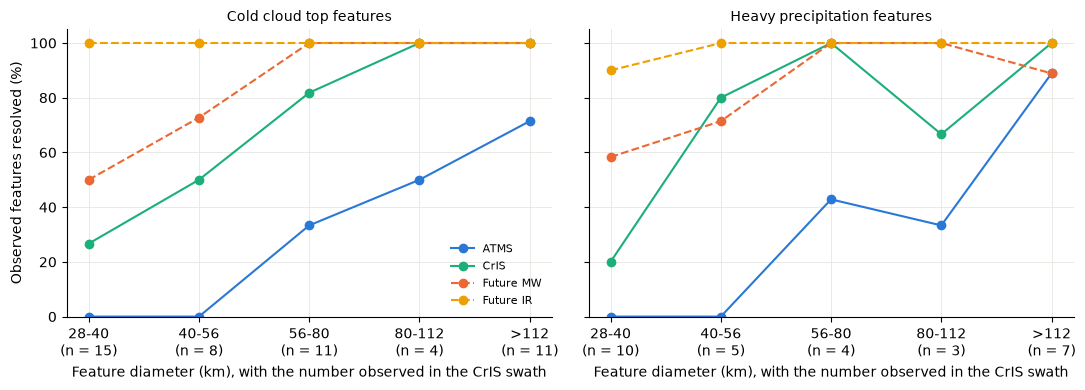

In [11]:
BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#8a8984",
    "#0b0b0b",
)
SENSOR_COLORS = {"ATMS": BLUE, "Future MW": ORANGE, "CrIS": AQUA, "Future IR": YELLOW}
SENSOR_STYLES = {"ATMS": "-", "Future MW": "--", "CrIS": "-", "Future IR": "--"}
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
    }
)

edges = np.array([EFFECTIVE_RESOLUTION_KM, 40, 56, 80, 112, np.inf])
labels = [f"{EFFECTIVE_RESOLUTION_KM}-40", "40-56", "56-80", "80-112", ">112"]
results["size_class"] = pd.cut(results.diameter_km, edges, labels=labels, right=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, kind in zip(axes, KINDS):
    of_kind = results[results.kind == kind]
    observed = of_kind[of_kind.observed]
    by_size = (
        observed.groupby(["sensor", "size_class"], observed=False)
        .resolved.mean()
        .unstack()
        .loc[sensors.index]
        * 100
    )
    for sensor in sensors.index:
        ax.plot(
            labels,
            by_size.loc[sensor],
            marker="o",
            color=SENSOR_COLORS[sensor],
            ls=SENSOR_STYLES[sensor],
            label=sensor,
        )
    counts = (
        observed[observed.sensor == "CrIS"].groupby("size_class", observed=False).size()
    )
    ax.set_xticks(
        range(len(labels)), [f"{label}\n(n = {n})" for label, n in zip(labels, counts)]
    )
    ax.set(
        xlabel="Feature diameter (km), with the number observed in the CrIS swath",
        title=f"{kind.capitalize()} features",
        ylim=(0, 105),
    )
    ax.title.set_fontsize(10)
axes[0].set_ylabel("Observed features resolved (%)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

The figure shows, by size, the share of the observed features that each sensor resolves (in contrast to the monsoon OSSE, of the features observed rather than of all features, so that it shows resolution alone). The sensors differ most for the smallest features (28 to 56 km), which ATMS does not resolve at all and a future infrared sounder nearly always resolves, and least for those larger than 112 km, which every sensor resolves except some that the ATMS swath (and so also a future microwave sounder's) views only in part at its edge. The counts per size class are small (3 to 15 features), so the shares of a class are uncertain by tens of percentage points.

## Trade the Constellation Design

As in the [monsoon OSSE](RunOSSEMonsoon.ipynb), this section trades the number of satellites and their orbit planes, with the same design space: sun-synchronous orbits at 830 km in `P` planes whose ascending equator crossing times are spread evenly over 12 hours from 13:30, each with the same number of evenly spaced satellites, at most six in all (14 designs), each carrying both swaths. The phases of the planes are uncertain parameters, drawn at random in `N_DRAWS` replicates with common random numbers, and a cache of the looks of each satellite is shared by the designs of a replicate (see the monsoon OSSE for these). The current constellation (NOAA-20 and NOAA-21) is evaluated for reference.

Unlike the monsoon OSSE, which trades over two weeks of convection, the trade is over the storm's two days, which is all the storm there is: its conclusions apply to this storm. Two days are few, so the phases of the satellites matter more, and the trade uses more replicates (`N_DRAWS`, twelve).

In [12]:
from datetime import time as time_of_day

from tatc.schemas import SunSynchronousOrbit
from tatc.tradespace import (
    Derived,
    DesignSpace,
    Integer,
    Repeat,
    SatelliteCache,
    Study,
    Uncertain,
)

N_DRAWS = (
    12  # replicates of each design: random phases of the satellites in their planes
)

# the design space: P planes whose ascending equator crossing times are spread evenly over 12 hours from 13:30, each
# with the same number of satellites at a random phase, for at most 6 satellites
space = DesignSpace(
    per_plane=Integer(1, 6),
    planes=Repeat(
        DesignSpace(
            crossing=Derived(lambda d: (13.5 + 12 * d.index / d.planes.count) % 24),
            phase=Uncertain.uniform(0, 360),
        ),
        count=Integer(1, 6),
    ),
    constraints=[lambda d: d.planes.count * d.per_plane <= 6],
)


def build(design):
    """The satellites of a design: in sun-synchronous orbits at 830 km, evenly spaced in each plane from its phase."""
    members = []
    for p, plane in enumerate(design.planes):
        crossing = time_of_day(
            int(plane.crossing), round(60 * (plane.crossing % 1)) % 60
        )
        for s in range(design.per_plane):
            orbit = SunSynchronousOrbit(
                altitude=830e3,
                equator_crossing_time=crossing,
                epoch=start,
                true_anomaly=(plane.phase + 360 * s / design.per_plane) % 360,
            )
            members.append(sounder_satellite(f"plane {p + 1} satellite {s + 1}", orbit))
    return members


def evaluate(members, cache=None):
    """The share (%) of the features of each kind that each sensor observes and resolves, flown on the members, with
    their looks from a cache of the looks of each satellite (in the order of the features and times), if any.
    """
    if cache is None:
        looks = collect_looks(members, duration, features)
    else:
        looks = cache(members).sort_values(
            ["feature", "time"], kind="stable", ignore_index=True
        )
    return (
        assess(looks, features, members)
        .groupby(["kind", "sensor"])[["observed", "resolved"]]
        .mean()
        .mul(100)
    )


# the looks of each satellite, cached by its orbit and instruments (not its name)
trade_looks = SatelliteCache(
    lambda satellite: collect_looks([satellite], duration, features)
)
study = Study(
    space,
    build,
    lambda members: evaluate(members, trade_looks),
    replicates=N_DRAWS,
    n_jobs=N_DRAWS,
    chunks_per_job=1,
)
trade = study.run()
trade["planes"] = trade["planes.count"]
trade["satellites"] = trade.planes * trade.per_plane
trade["design"] = (
    trade.planes.astype(str) + " plane(s) x " + trade.per_plane.astype(str)
)
# the current constellation, for reference
current = evaluate(satellites).assign(
    satellites=len(satellites),
    design=f"current ({len(satellites)} in the 13:30 plane)",
)

# features resolved by each sensor, % of the features of each kind, averaged over the replicates
trade_summary = pd.concat([trade, current.reset_index()]).pivot_table(
    index=["satellites", "design"], columns=["kind", "sensor"], values="resolved"
)
trade_summary[[(kind, sensor) for kind in KINDS for sensor in sensors.index]].round(1)

kind                                      cold cloud top                  \
sensor                                              ATMS  CrIS Future MW   
satellites design                                                          
1          1 plane(s) x 1                            1.5   3.0       4.3   
2          1 plane(s) x 2                            2.8   5.9       8.7   
           2 plane(s) x 1                            2.6   5.0       7.9   
           current (2 in the 13:30 plane)            3.1   5.9       9.2   
3          1 plane(s) x 3                            4.0   9.2      13.3   
           3 plane(s) x 1                            4.2   8.3      12.4   
4          1 plane(s) x 4                            5.0  11.3      15.7   
           2 plane(s) x 2                            5.1  10.4      16.0   
           4 plane(s) x 1                            4.8   9.7      15.3   
5          1 plane(s) x 5                            5.1  11.5      16.0   
           5 plane(s) x 1                            6.3  11.7      17.7   
6          1 plane(s) x 6                            5.3  12.1      16.6   
           2 plane(s) x 3                            7.3  15.6      23.9   
           3 plane(s) x 2                            7.8  16.1      24.5   
           6 plane(s) x 1                            6.9  14.3      21.6   

kind                                                heavy precipitation        \
sensor                                    Future IR                ATMS  CrIS   
satellites design                                                               
1          1 plane(s) x 1                       4.3                 1.0   1.8   
2          1 plane(s) x 2                       8.7                 1.8   3.7   
           2 plane(s) x 1                       8.0                 1.7   3.9   
           current (2 in the 13:30 plane)       9.0                 2.1   3.3   
3          1 plane(s) x 3                      13.4                 2.8   5.6   
           3 plane(s) x 1                      12.2                 2.7   6.7   
4          1 plane(s) x 4                      15.9                 3.3   6.7   
           2 plane(s) x 2                      16.0                 3.5   8.5   
           4 plane(s) x 1                      15.1                 3.4   8.2   
5          1 plane(s) x 5                      16.3                 3.4   7.0   
           5 plane(s) x 1                      17.8                 4.2  10.0   
6          1 plane(s) x 6                      16.9                 3.6   7.4   
           2 plane(s) x 3                      24.1                 5.3  12.6   
           3 plane(s) x 2                      23.9                 5.4  12.9   
           6 plane(s) x 1                      21.7                 5.2  12.5   

kind                                                           
sensor                                    Future MW Future IR  
satellites design                                              
1          1 plane(s) x 1                       2.8       2.7  
2          1 plane(s) x 2                       5.6       5.5  
           2 plane(s) x 1                       6.2       6.2  
           current (2 in the 13:30 plane)       5.3       4.9  
3          1 plane(s) x 3                       8.4       8.3  
           3 plane(s) x 1                      10.4      10.9  
4          1 plane(s) x 4                       9.9       9.9  
           2 plane(s) x 2                      13.2      13.4  
           4 plane(s) x 1                      14.3      14.6  
5          1 plane(s) x 5                      10.1      10.0  
           5 plane(s) x 1                      17.1      17.7  
6          1 plane(s) x 6                      10.5      10.5  
           2 plane(s) x 3                      20.0      20.5  
           3 plane(s) x 2                      20.7      21.6  
           6 plane(s) x 1                      20.8      21.8

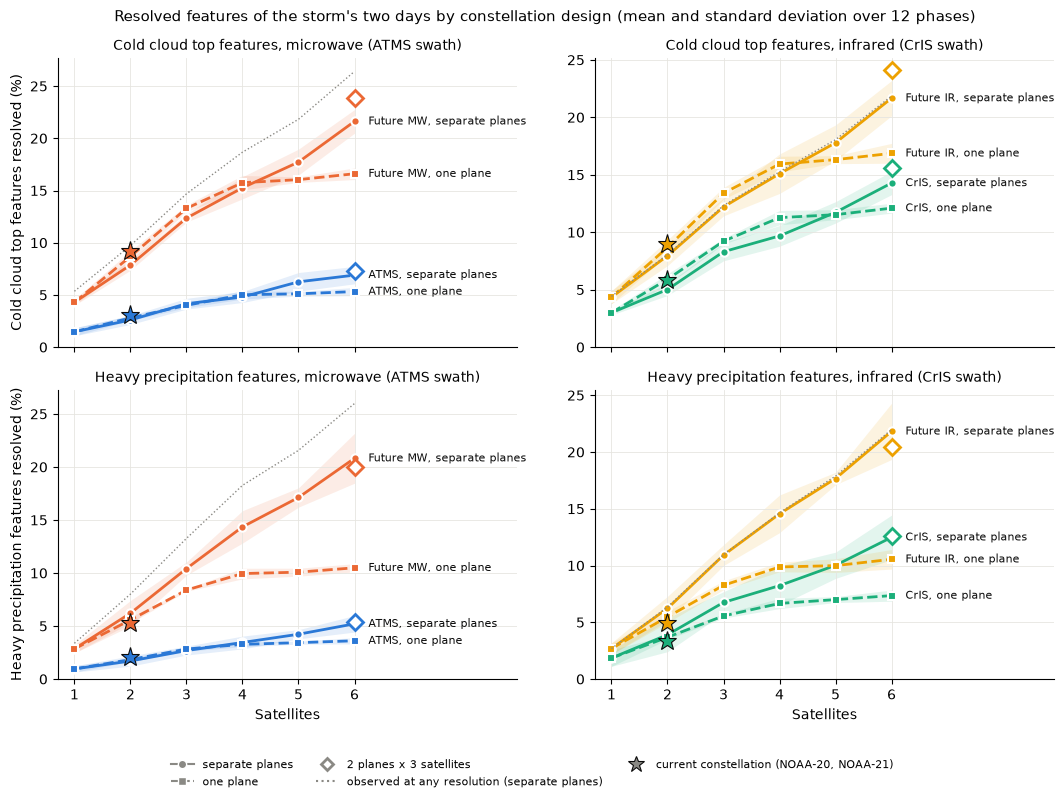

In [13]:
STRATEGIES = {"separate planes": ("-", "o"), "one plane": ("--", "s")}

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for row, kind in enumerate(KINDS):
    for ax, (title, pair) in zip(
        axes[row],
        {
            "Microwave (ATMS swath)": ("ATMS", "Future MW"),
            "Infrared (CrIS swath)": ("CrIS", "Future IR"),
        }.items(),
    ):
        of_kind_trade = trade[trade.kind == kind]
        ends = []
        for sensor in pair:
            color = SENSOR_COLORS[sensor]
            for strategy, (ls, marker) in STRATEGIES.items():
                selected = of_kind_trade[
                    (of_kind_trade.sensor == sensor)
                    & (
                        (of_kind_trade.planes == 1)
                        if strategy == "one plane"
                        else (of_kind_trade.per_plane == 1)
                    )
                ]
                stats = selected.groupby("satellites")["resolved"].agg(["mean", "std"])
                ax.fill_between(
                    stats.index,
                    stats["mean"] - stats["std"],
                    stats["mean"] + stats["std"],
                    color=color,
                    alpha=0.12,
                    lw=0,
                )
                ax.plot(
                    stats.index,
                    stats["mean"],
                    ls=ls,
                    marker=marker,
                    ms=6,
                    lw=2,
                    color=color,
                    mec="white",
                    mew=1.5,
                )
                ends.append([stats["mean"].iloc[-1], f"{sensor}, {strategy}"])
            two_planes = of_kind_trade[
                (of_kind_trade.sensor == sensor)
                & (of_kind_trade.planes == 2)
                & (of_kind_trade.per_plane == 3)
            ]["resolved"].mean()
            ax.plot(
                6,
                two_planes,
                marker="D",
                ms=8,
                color="white",
                mec=color,
                mew=2,
                zorder=3,
            )
            # the current constellation
            ax.plot(
                len(satellites),
                current.loc[(kind, sensor), "resolved"],
                marker="*",
                ms=14,
                color=color,
                mec=INK,
                mew=0.8,
                zorder=4,
            )
        # direct labels at the line ends, nudged apart so that they do not overlap
        ends.sort()
        for i in range(1, len(ends)):
            ends[i][0] = max(ends[i][0], ends[i - 1][0] + 1.6)
        for y, label in ends:
            ax.annotate(
                label,
                (6, y),
                xytext=(10, 0),
                textcoords="offset points",
                va="center",
                fontsize=8,
                color=INK,
            )
        # the features observed at any resolution, with separate planes: the most that any sensor can resolve
        observed = (
            of_kind_trade[
                (of_kind_trade.sensor == pair[0]) & (of_kind_trade.per_plane == 1)
            ]
            .groupby("satellites")["observed"]
            .mean()
        )
        ax.plot(observed.index, observed, color=GRAY, lw=1, ls=":")
        ax.set(
            title=f"{kind.capitalize()} features, {title[0].lower()}{title[1:]}",
            xticks=range(1, 7),
            xlim=(0.7, 8.9),
            ylim=(0, None),
        )
        ax.title.set_fontsize(10)
    axes[row, 0].set_ylabel(f"{kind.capitalize()} features resolved (%)")
for ax in axes[1]:
    ax.set_xlabel("Satellites")
legend = [
    plt.Line2D(
        [], [], color=GRAY, ls="-", marker="o", mec="white", label="separate planes"
    ),
    plt.Line2D([], [], color=GRAY, ls="--", marker="s", mec="white", label="one plane"),
    plt.Line2D(
        [],
        [],
        color=GRAY,
        ls="none",
        marker="D",
        mfc="white",
        mew=2,
        label="2 planes x 3 satellites",
    ),
    plt.Line2D(
        [], [], color=GRAY, ls=":", label="observed at any resolution (separate planes)"
    ),
    plt.Line2D(
        [],
        [],
        color=GRAY,
        ls="none",
        marker="*",
        ms=12,
        mec=INK,
        mew=0.8,
        label=f"current constellation ({', '.join(tles)})",
    ),
]
fig.legend(handles=legend, loc="lower center", ncol=3, fontsize=8, frameon=False)
fig.suptitle(
    f"Resolved features of the storm's two days by constellation design (mean and standard deviation over {N_DRAWS} phases)",
    fontsize=11,
)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Over the storm's two days, the current constellation resolves 3% (ATMS), 6% (CrIS), and 9% (either future sensor) of the cold cloud tops, and 2 to 5% of the patches of heavy precipitation, about as many as two satellites evenly spaced in one plane (the stars, on the lines of one plane).

* **Satellites in one plane saturate,** as over the monsoon. With a future sensor, four to six satellites in the 13:30 plane resolve 16 to 17% of the cold cloud tops and 10 to 11% of the patches of heavy precipitation, hardly more than four, because they all observe at the same local times.
* **Separate planes pay off most for the heavy precipitation.** With a future sensor, six satellites in separate planes resolve 21 to 22% of either kind: twice as many patches of heavy precipitation as six satellites in one plane, but only about a quarter more cold cloud tops.
* **Two or three planes do as well as six.** Six satellites in two or three planes resolve 24 to 25% of the cold cloud tops with a future sensor, more than in six planes, and 20 to 22% of the patches of heavy precipitation, as many.
* **Whether resolution or planes matter more depends on the feature.** For the cold cloud tops, a future infrared sounder on six satellites in one plane resolves more (17%) than CrIS on six in separate planes (14%); for the heavy precipitation, the reverse (10.5% and 12.5%).
* **ATMS is limited by resolution.** It resolves at most 8% of the cold cloud tops and 5% of the patches of heavy precipitation in any design.

These conclusions apply to this storm over two days, sampled at random phases of the satellites: the spread between the phases (the shaded bands) is wider than over the monsoon's two weeks, and other storms, at other stages and times of day, would differ.

## Limitations

The limitations of the monsoon OSSE apply, notably that resolution is geometric (without the response of each footprint), that the future sensors are assumed to share the swaths and platforms of ATMS and CrIS, and that features are snapshots. In addition:

* **One storm, two days.** The results describe one simulated storm at one stage of its life, sampled by one realization of the satellites' passes (the constellation trade averages over the phases of the satellites, not over storms). Other storms, stages, and dates (extend `start` and `duration`, or find other storms in the coarsened Nature Run) would be needed for statistics.
* **The study region is fitted to the storm.** Features of the storm's environment are counted only within the box around its track, so their number depends on the box.
* **The storm center is coarse.** The center is the minimum sea-level pressure of the 0.5 degree, hourly collection, interpolated to the frames, so it is uncertain by tens of kilometers, which matters little for the 500 km radius that attributes features to the storm.
* **The features are proxies.** Cold cloud tops and heavy precipitation identify where observations may be valuable; the quantities a sounder retrieves in a hurricane (the warm core, the temperature and humidity of its environment, the rain and ice of its rainbands) depend on its channels, and infrared sounders do not see beneath the cloud tops.
* **The Nature Run is not reality.** Its storm is simulated at 7 km, which does not resolve the eyewall of a strong hurricane, so its smallest features (and the precipitation rates within them) differ from those of a real storm.